# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import AgricultureVisionDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
import matplotlib.pyplot as plt

## Visualize images and masks

Total number of patches: 56944


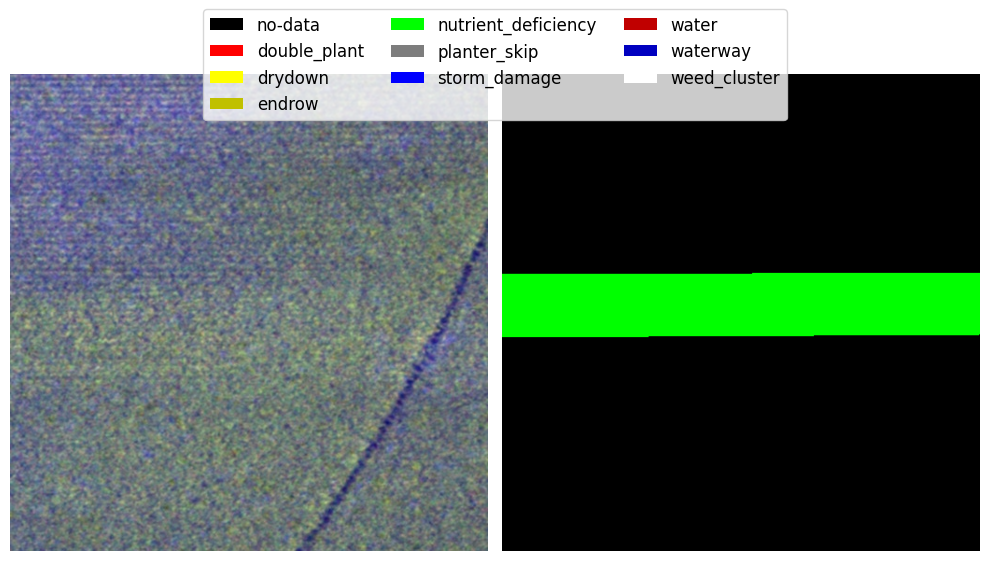

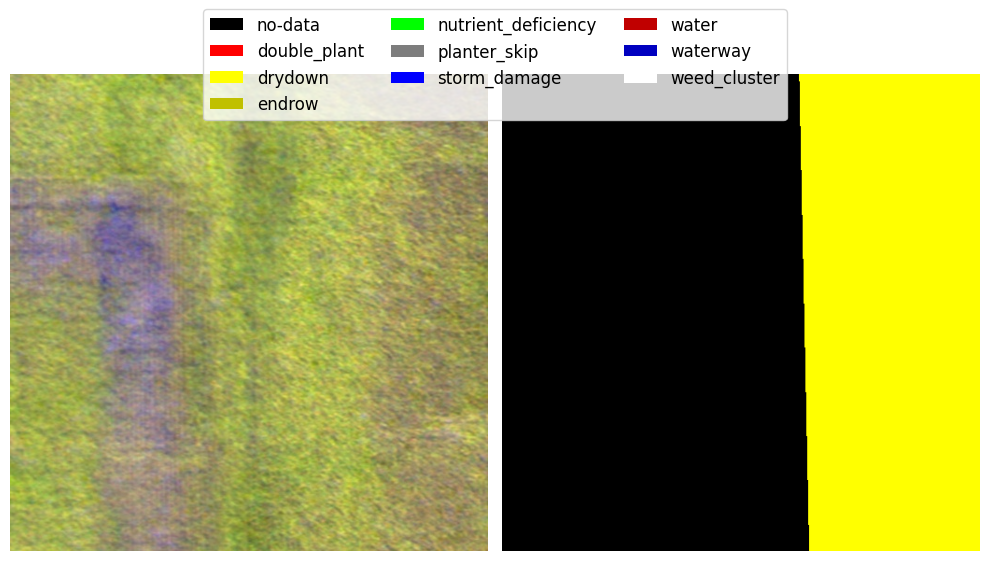

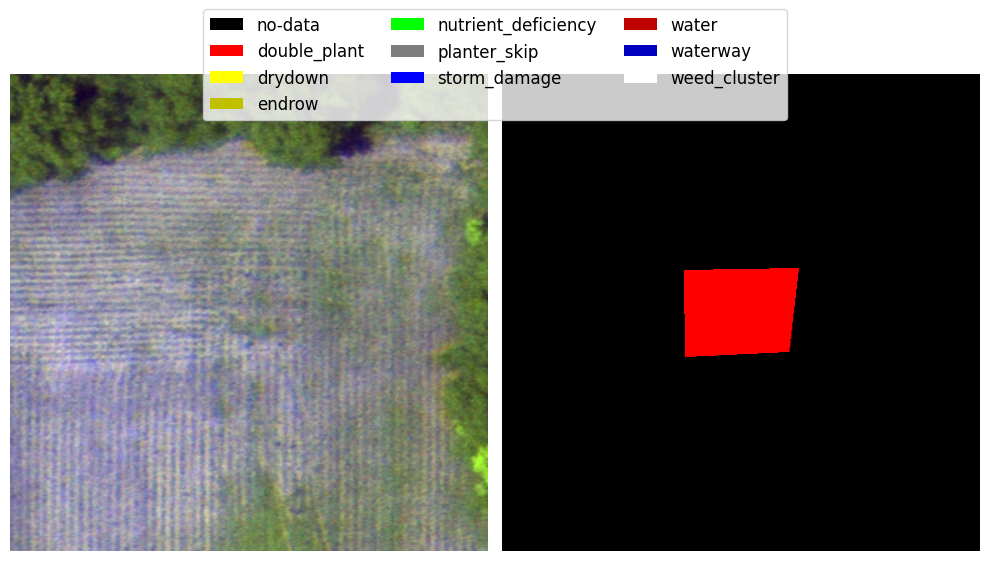

In [ ]:
dataset_config = {
    "data_dir": "./data/agriculture-vision/train"
}
dataset = AgricultureVisionDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(350);
dataset.show_image(1500);

In [5]:
dataset.data_distribution_table()

,Number of pixels
no-data,0.000000e+00
double_plant,1.263303e+08
drydown,1.838662e+09
endrow,1.355279e+08
nutrient_deficiency,1.108061e+09
planter_skip,2.830430e+07
storm_damage,2.777199e+07
water,1.496374e+08
waterway,1.411595e+08
weed_cluster,9.214196e+08


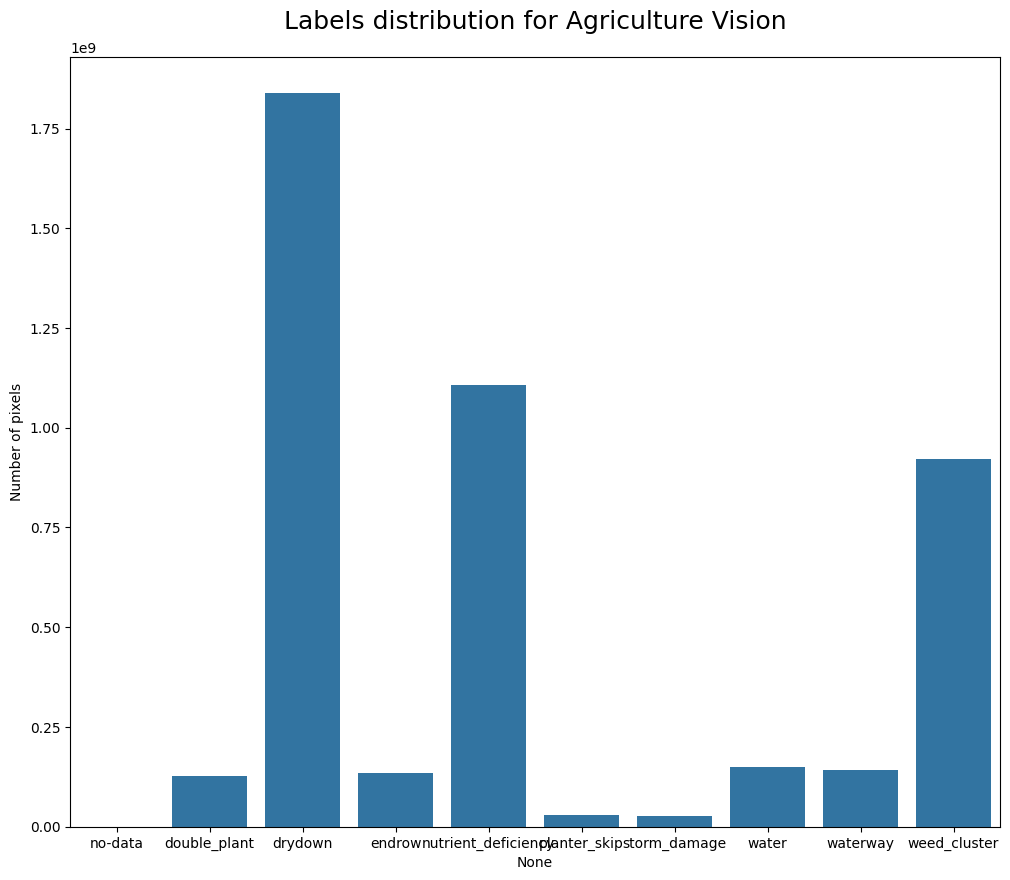

In [6]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/agriculture-vision/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = AgricultureVisionDataset(train_dataset_config)
len(train_dataset)

56944

## Create the model

In [ ]:
epochs = 1
model_directory = "./data/agriculture-vision"
model_config = {
    "num_classes": 10, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-11-05 07:46:07,935 INFO Starting training.
training: 100%|██████████| 3559/3559 [15:09:54<00:00, 15.34s/it]
2025-11-05 22:56:02,426 INFO epoch: 1, time: 54594, loss:  0.55306
testing on train set: 100%|██████████| 3559/3559 [12:22:43<00:00, 12.52s/it]  
2025-11-06 11:18:47,553 INFO IOU:0.40691588404079104, IOU mean:0.16784315614634276, IOU per Class:[0.         0.         0.53891889 0.         0.35992147 0.
 0.         0.44653983 0.         0.33305138]
2025-11-06 11:18:49,700 INFO Train loss: [0.43075746661258835]
2025-11-06 11:18:49,701 INFO Validation loss: []
2025-11-06 11:18:49,702 INFO Train time per epochs: [54594]
2025-11-06 11:18:49,702 INFO Finished training. training time: 54594


## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/agriculture-vision/val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = AgricultureVisionDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/agriculture-vision/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

18334


2025-11-07 08:09:28,722 INFO Loading checkpoint /home/dragik/data/FAIR_EO/agriculture-vision/checkpoint.pth.tar
2025-11-07 08:09:29,172 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/agriculture-vision/checkpoint.pth.tar at epoch 2
testing on test set: 100%|██████████| 1146/1146 [3:59:01<00:00, 12.51s/it] 


[{'IOU': 0.3776943295487979,
  'IOU mean': 0.147696954013886,
  'IOU per Class': array([0.        , 0.        , 0.52966985, 0.        , 0.30898828,
         0.        , 0.        , 0.44175848, 0.        , 0.19655294])}]

## Predictions

2025-11-07 12:29:47,984 INFO Loading checkpoint /home/dragik/data/FAIR_EO/agriculture-vision/checkpoint.pth.tar
2025-11-07 12:29:48,447 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/agriculture-vision/checkpoint.pth.tar at epoch 2


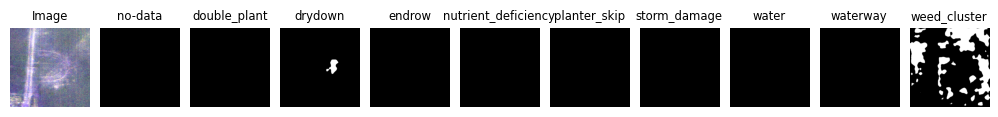

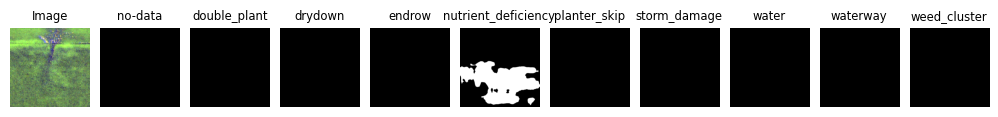

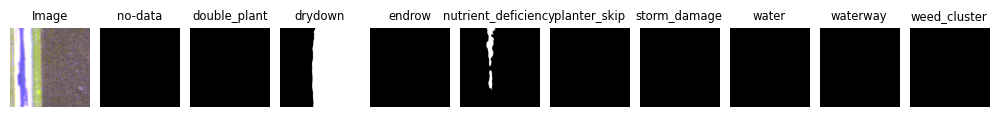

In [ ]:
model_path = "./data/agriculture-vision/checkpoint.pth.tar"
labels = ["no-data","double_plant","drydown","endrow","nutrient_deficiency","planter_skip","storm_damage","water","waterway","weed_cluster"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
plt.rcParams.update({'font.size': 7})

image = image_loader('./data/agriculture-vision/test/images/rgb/1FY8MBG8K_5848-1727-6360-2239.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/agriculture-vision/test/images/rgb/1NEDW647M_4393-802-4905-1314.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/agriculture-vision/test/images/rgb/1WULXE3BJ_761-5025-1273-5537.jpg')
fig = model.predict_masks(image, labels, transform)